# Khám phá dữ liệu học sinh (EDA)

Notebook này bắt đầu khám phá bộ dữ liệu tại `XGBoost/data/hoc_sinh.csv`: cấu trúc, chất lượng dữ liệu, phân phối điểm và nhãn môn tự chọn. Các bước chỉ đọc dữ liệu, không sửa CSV nguồn.

> Các thống kê và biểu đồ dưới đây chỉ mô tả dữ liệu thu thập được; chúng không chứng minh quan hệ nhân quả và không phải tư vấn môn học phù hợp cho từng học sinh. Không sử dụng mã học sinh làm đặc trưng phân tích.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

data_candidates = [
    Path.cwd() / "data" / "hoc_sinh.csv",
    Path.cwd().parent / "data" / "hoc_sinh.csv",
    Path.cwd() / "data" / "hoc_sinh.csv",
]
DATA_PATH = next((path.resolve() for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    checked = "\n".join(str(path) for path in data_candidates)
    raise FileNotFoundError(f"Không tìm thấy CSV. Đã kiểm tra:\n{checked}")

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", dtype={"ma_hoc_sinh": "string"})
print(f"Nguồn dữ liệu: {DATA_PATH}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]:,} cột")

Nguồn dữ liệu: D:\I. KhongPhanLoai\DuAnVietBao\student-class-selection-dss\XGBoost\data\hoc_sinh.csv
Kích thước: 10,000 dòng × 62 cột


## 1. Tổng quan cấu trúc

Xem một vài bản ghi, tên cột và kiểu dữ liệu để phân biệt mã học sinh, điểm các môn theo khối lớp và nhãn môn tự chọn.

In [3]:
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum()}))

ID_COLUMN = "ma_hoc_sinh"
score_columns = [
    column for column in df.columns
    if any(column.endswith(f"_lop{grade}") for grade in range(6, 10))
]
target_columns = [
    column for column in df.columns
    if column != ID_COLUMN and column not in score_columns
]
print(f"Số cột điểm theo khối lớp: {len(score_columns)}")
print(f"Số cột nhãn môn tự chọn: {len(target_columns)}")
print("Cột nhãn:", target_columns)

,ma_hoc_sinh,toan_lop6,toan_lop7,toan_lop8,toan_lop9,ngu_van_lop6,ngu_van_lop7,ngoai_ngu_lop6,ngoai_ngu_lop7,ngoai_ngu_lop8,ngoai_ngu_lop9,khoa_hoc_tu_nhien_lop6,khoa_hoc_tu_nhien_lop7,khoa_hoc_tu_nhien_lop8,khoa_hoc_tu_nhien_lop9,lich_su_dia_ly_lop6,lich_su_dia_ly_lop7,lich_su_dia_ly_lop8,lich_su_dia_ly_lop9,giao_duc_cong_dan_lop6,giao_duc_cong_dan_lop7,giao_duc_cong_dan_lop8,giao_duc_cong_dan_lop9,tin_hoc_lop6,tin_hoc_lop7,tin_hoc_lop8,tin_hoc_lop9,cong_nghe_lop6,cong_nghe_lop7,cong_nghe_lop8,cong_nghe_lop9,giao_duc_the_chat_lop6,giao_duc_the_chat_lop7,giao_duc_the_chat_lop8,giao_duc_the_chat_lop9,am_nhac_lop6,am_nhac_lop7,am_nhac_lop8,am_nhac_lop9,mi_thuat_lop6,mi_thuat_lop7,mi_thuat_lop8,mi_thuat_lop9,noi_dung_giao_duc_dia_phuong_lop6,noi_dung_giao_duc_dia_phuong_lop7,noi_dung_giao_duc_dia_phuong_lop8,noi_dung_giao_duc_dia_phuong_lop9,hoat_dong_trai_nghiem_huong_nghiep_lop6,hoat_dong_trai_nghiem_huong_nghiep_lop7,hoat_dong_trai_nghiem_huong_nghiep_lop8,hoat_dong_trai_nghiem_huong_nghiep_lop9,ngu_van_lop8,ngu_van_lop9,Vật lý,Hóa học,Sinh học,Công nghệ,Tin học,Địa lý,Giáo dục kinh tế và pháp luật,Âm nhạc,Mỹ thuật
0,A83BD9C8-2B6D-19BB-2749-5D55911B5968,2,2,10,5,3,6,10,9,5,8,6,4,3,9,0,2,8,4,2,4,4,1,1,8,0,0,1,10,9,3,3,8,1,4,1,4,7,3,10,3,10,9,4,0,7,7,8,5,9,4,9,10,1,0,0,0,1,1,1,0,0
1,189B56EF-3DAF-A1DF-6A5B-AA84F882D776,10,7,9,5,6,6,3,2,3,9,1,9,4,4,0,2,3,9,8,1,3,0,5,3,8,3,10,3,8,8,1,9,5,4,1,4,3,7,7,7,9,7,3,10,2,2,8,6,3,7,6,6,1,1,1,1,0,0,0,0,0
2,F263E3AD-1EC6-4749-C577-E2D68B42D5A2,8,1,8,3,3,2,1,9,3,2,4,1,8,4,4,5,4,8,2,2,9,4,0,7,2,3,6,7,8,3,5,2,1,5,7,4,7,2,6,0,7,8,8,3,0,10,5,1,5,5,1,0,0,1,1,0,1,0,0,1,0
3,1AA6CC74-DAAA-0B71-1949-28DD0CAA9886,0,3,4,2,8,9,10,6,9,7,1,1,3,3,1,5,1,7,3,1,1,9,5,3,9,9,8,5,1,10,9,10,1,10,9,1,7,5,1,9,5,3,9,2,4,6,5,2,2,2,10,10,1,0,0,1,0,0,1,0,1
4,D811AEE5-395D-3AC2-1672-7D0342C12AC1,4,2,6,6,10,1,5,3,4,6,9,8,5,7,6,8,9,9,7,8,9,4,10,4,1,5,1,3,1,5,5,5,6,8,1,4,4,9,2,8,2,0,9,5,7,9,5,4,8,8,0,0,0,1,0,0,0,1,0,0,1


,dtype,non_null
ma_hoc_sinh,string,10000
toan_lop6,int64,10000
toan_lop7,int64,10000
toan_lop8,int64,10000
toan_lop9,int64,10000
ngu_van_lop6,int64,10000
ngu_van_lop7,int64,10000
ngoai_ngu_lop6,int64,10000
ngoai_ngu_lop7,int64,10000
ngoai_ngu_lop8,int64,10000


Số cột điểm theo khối lớp: 52
Số cột nhãn môn tự chọn: 9
Cột nhãn: ['Vật lý', 'Hóa học', 'Sinh học', 'Công nghệ', 'Tin học', 'Địa lý', 'Giáo dục kinh tế và pháp luật', 'Âm nhạc', 'Mỹ thuật']


## 2. Kiểm tra chất lượng dữ liệu

Kiểm tra giá trị thiếu, dòng trùng, mã học sinh trùng, miền giá trị điểm `[0, 10]` và các giá trị nhãn. Các kiểm tra này chỉ báo cáo vấn đề, không tự ý sửa hoặc loại bỏ bản ghi.

In [4]:
missing_by_column = df.isna().sum().sort_values(ascending=False)
print("Giá trị thiếu theo cột (chỉ cột có thiếu):")
display(missing_by_column[missing_by_column > 0].to_frame("missing_count"))
print(f"Số dòng trùng hoàn toàn: {df.duplicated().sum():,}")
if ID_COLUMN in df.columns:
    print(f"Số mã học sinh trùng (không tính thiếu): {df[ID_COLUMN].dropna().duplicated().sum():,}")

numeric_scores = df[score_columns].apply(pd.to_numeric, errors="coerce")
invalid_score_mask = numeric_scores.isna() | ~numeric_scores.ge(0) | ~numeric_scores.le(10)
invalid_scores = numeric_scores.where(invalid_score_mask).stack().rename("value")
print(f"Số ô điểm không phải số hoặc ngoài [0, 10]: {len(invalid_scores):,}")
display(invalid_scores.head(20).to_frame())

for column in target_columns:
    observed = sorted(df[column].dropna().astype(str).str.strip().str.lower().unique())
    allowed = {"0", "1", "yes", "no"}
    unexpected = sorted(set(observed) - allowed)
    if unexpected:
        print(f"Nhãn bất thường ở {column}: {unexpected}")
print("Hoàn tất kiểm tra nhãn; giá trị hợp lệ dự kiến: 0/1 hoặc Yes/No.")

Giá trị thiếu theo cột (chỉ cột có thiếu):


,missing_count


Số dòng trùng hoàn toàn: 0
Số mã học sinh trùng (không tính thiếu): 0
Số ô điểm không phải số hoặc ngoài [0, 10]: 0


,,value


Hoàn tất kiểm tra nhãn; giá trị hợp lệ dự kiến: 0/1 hoặc Yes/No.


## 3. Thống kê điểm theo môn và khối lớp

In [5]:
score_summary = numeric_scores.describe().T[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)
display(score_summary)

score_long = numeric_scores.melt(var_name="subject_grade", value_name="score")
score_long["grade"] = score_long["subject_grade"].str.extract(r"_lop([6-9])$")
score_long["subject"] = score_long["subject_grade"].str.replace(r"_lop[6-9]$", "", regex=True)
grade_summary = score_long.groupby("grade", observed=True)["score"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)
display(grade_summary)

,count,mean,std,min,25%,50%,75%,max
toan_lop6,10000.0,5.01,2.63,0.0,3.0,5.0,7.0,10.0
toan_lop7,10000.0,4.98,2.64,0.0,3.0,5.0,7.0,10.0
toan_lop8,10000.0,5.01,2.66,0.0,3.0,5.0,7.0,10.0
toan_lop9,10000.0,5.00,2.67,0.0,3.0,5.0,7.0,10.0
ngu_van_lop6,10000.0,5.02,2.62,0.0,3.0,5.0,7.0,10.0
ngu_van_lop7,10000.0,5.00,2.62,0.0,3.0,5.0,7.0,10.0
ngoai_ngu_lop6,10000.0,5.00,2.64,0.0,3.0,5.0,7.0,10.0
ngoai_ngu_lop7,10000.0,5.01,2.62,0.0,3.0,5.0,7.0,10.0
ngoai_ngu_lop8,10000.0,5.01,2.64,0.0,3.0,5.0,7.0,10.0
ngoai_ngu_lop9,10000.0,5.00,2.67,0.0,3.0,5.0,7.0,10.0


,count,mean,median,std,min,max
grade,,,,,,
6,130000,5.00,5.0,2.63,0,10
7,130000,4.98,5.0,2.63,0,10
8,130000,4.99,5.0,2.71,0,10
9,130000,4.99,5.0,2.79,0,10


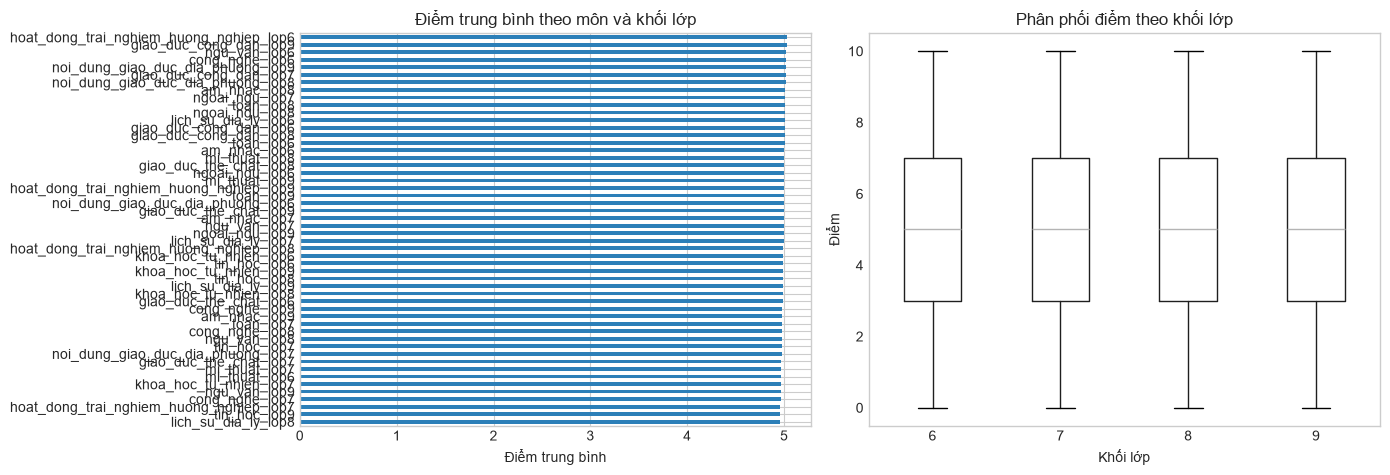

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
numeric_scores.mean().sort_values().plot.barh(ax=axes[0], color="#2c7fb8")
axes[0].set_title("Điểm trung bình theo môn và khối lớp")
axes[0].set_xlabel("Điểm trung bình")
axes[0].set_ylabel("")
score_long.boxplot(column="score", by="grade", ax=axes[1], grid=False)
axes[1].set_title("Phân phối điểm theo khối lớp")
axes[1].set_xlabel("Khối lớp")
axes[1].set_ylabel("Điểm")
fig.suptitle("")
fig.tight_layout()
plt.show()

## 4. Phân phối lựa chọn môn

Chuẩn hóa nhãn sang 0/1 trong một bản sao dùng cho thống kê; dữ liệu nguồn không bị thay đổi. Tổng số môn được chọn mỗi học sinh giúp kiểm tra cấu trúc nhãn, không mặc định rằng mỗi em phải chọn một số môn cố định.

In [7]:
label_values = {"yes": 1, "no": 0, "1": 1, "0": 0}
targets = pd.DataFrame(index=df.index)
for column in target_columns:
    normalized = df[column].astype("string").str.strip().str.lower()
    targets[column] = normalized.map(label_values)

target_summary = pd.DataFrame({
    "No (0)": (targets == 0).sum(),
    "Yes (1)": (targets == 1).sum(),
    "Missing_or_unrecognized": targets.isna().sum(),
})
target_summary["Yes_rate"] = (target_summary["Yes (1)"] / len(targets)).round(4)
display(target_summary)

selected_count = targets.sum(axis=1, min_count=len(target_columns))
print("Số môn được chọn mỗi học sinh:")
display(selected_count.value_counts(dropna=False).sort_index().rename("students").to_frame())
print(f"Số nhãn thiếu/không nhận diện: {int(targets.isna().sum().sum()):,}")

,No (0),Yes (1),Missing_or_unrecognized,Yes_rate
Vật lý,6367,3633,0,0.3633
Hóa học,6338,3662,0,0.3662
Sinh học,6457,3543,0,0.3543
Công nghệ,6258,3742,0,0.3742
Tin học,6301,3699,0,0.3699
Địa lý,6392,3608,0,0.3608
Giáo dục kinh tế và pháp luật,6333,3667,0,0.3667
Âm nhạc,6414,3586,0,0.3586
Mỹ thuật,6296,3704,0,0.3704


Số môn được chọn mỗi học sinh:


,students
0,305
1,741
2,1170
3,1373
4,6411


Số nhãn thiếu/không nhận diện: 0


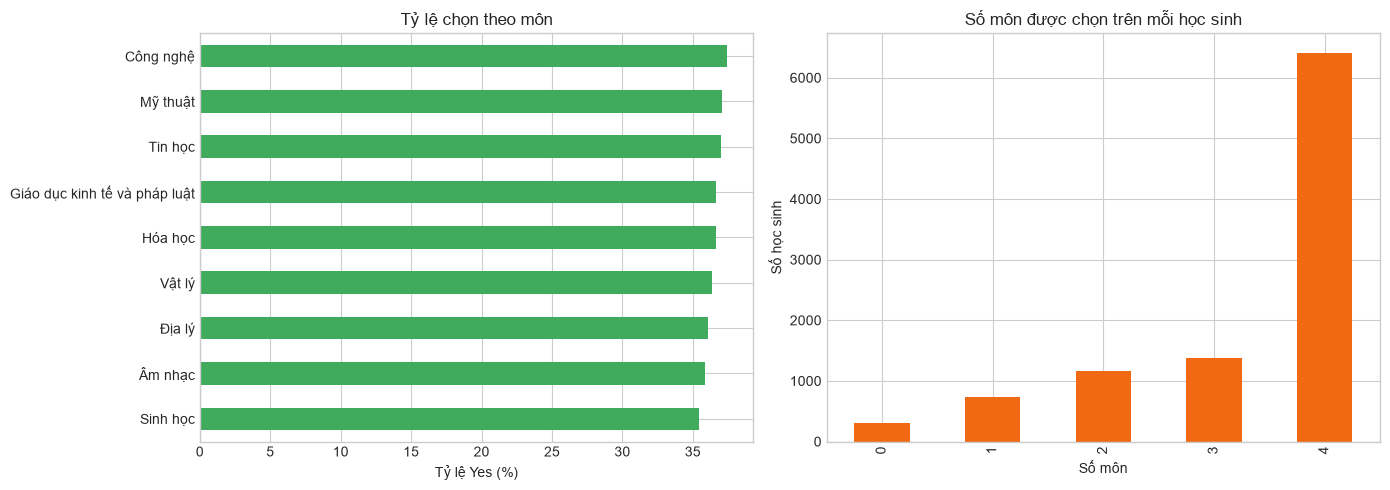

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
target_summary["Yes_rate"].sort_values().mul(100).plot.barh(
    ax=axes[0], color="#41ab5d"
)
axes[0].set_title("Tỷ lệ chọn theo môn")
axes[0].set_xlabel("Tỷ lệ Yes (%)")
axes[0].set_ylabel("")
selected_count.value_counts().sort_index().plot.bar(ax=axes[1], color="#f16913")
axes[1].set_title("Số môn được chọn trên mỗi học sinh")
axes[1].set_xlabel("Số môn")
axes[1].set_ylabel("Số học sinh")
fig.tight_layout()
plt.show()

## 5. Câu hỏi tiếp theo

- So sánh phân phối điểm giữa nhóm chọn và không chọn từng môn; báo cáo độ lớn khác biệt kèm mức độ bất định.
- Xem tương quan giữa các môn/khối lớp và giữa các nhãn, đồng thời tránh diễn giải tương quan thành nguyên nhân.
- Đánh giá tính đại diện và nguồn gốc dữ liệu trước khi đưa ra kết luận hoặc dùng kết quả cho quyết định thực tế.

Kết luận ban đầu nên được ghi kèm số lượng mẫu, cách xử lý nhãn và giới hạn dữ liệu.